# Data

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, sql

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .3})

In [2]:
gasoline = data.dataset("gasoline")
distillate = data.dataset("distillate")
bunker = data.dataset("bunker")

In [3]:
gasoline.shape, distillate.shape, bunker.shape

((321, 6), (321, 8), (321, 7))

In [4]:
gasoline.head()

,demand,inc,payrolls,vmt,real_price,product_supplied_4wk
month,,,,,,
2000-01-01,"7,653.00","9,735.90","130,783.00","221,856.00",0.75,"8,055.00"
2000-02-01,"8,291.00","9,799.90","131,011.00","221,465.00",0.76,"8,231.50"
2000-03-01,"8,305.00","9,837.90","131,120.00","203,442.00",0.81,"8,213.75"
2000-04-01,"8,375.00","9,864.00","131,604.00","199,261.00",0.89,"8,431.00"
2000-05-01,"8,661.00","9,913.70","131,884.00","232,490.00",0.86,"8,407.75"


In [5]:
distillate.dtypes

demand                  float64
hdd                     float64
hdd_oil                 float64
ind                     float64
ind_manuf               float64
truck                   float64
real_price              float64
product_supplied_4wk    float64
dtype: object

In [6]:
bunker.index.min(), bunker.index.max(), pd.infer_freq(bunker.index)

(Timestamp('2000-01-01 00:00:00'), Timestamp('2026-09-01 00:00:00'), 'MS')

In [7]:
bunker.tail(3)

,demand,brent,bunker_calls,bunker_calls_gt,cargo,tankers,wtr
month,,,,,,,
2026-07-01,139.37,83.73,"3,618.00","194,947.94","51,030.80","2,251.00",114.35
2026-08-01,140.18,83.73,"3,675.00","202,599.02","51,890.06","2,267.00",116.41
2026-09-01,NaN,83.73,"3,588.00","201,793.95","50,436.34","2,203.00",116.81


## SQL

In [8]:
sql.query("SELECT COUNT(*) FROM demand")

,count_star()
0,2338


In [9]:
sql.query("SELECT COUNT(*) FROM predictors")

,count_star()
0,20355


In [10]:
sql.query("""
    SELECT product, unit, MIN(period_end), MAX(period_end), COUNT(*)
    FROM demand GROUP BY 1, 2 ORDER BY 1
""")

,product,unit,min(period_end),max(period_end),count_star()
0,bunker,kt/d,1995-01-31,2026-08-31,380
1,distillate,kb/d,1945-01-31,2026-07-31,979
2,gasoline,kb/d,1945-01-31,2026-07-31,979


In [11]:
sql.query("""
    SELECT product, variable, MIN(period_end), MAX(period_end), COUNT(*)
    FROM predictors GROUP BY 1, 2 ORDER BY 1, 2
""")

,product,variable,min(period_end),max(period_end),count_star()
0,bunker,brent,1992-01-31,2026-07-31,415
1,bunker,bunker_calls,1993-01-31,2026-08-31,404
2,bunker,bunker_calls_gt,1993-01-31,2026-08-31,404
3,bunker,cargo,1995-01-31,2026-08-31,380
4,bunker,tankers,2002-01-31,2026-08-31,296
5,bunker,wtr,2000-01-31,2026-07-31,319
6,distillate,cpi,1947-01-31,2026-08-31,955
7,distillate,exports,1945-01-31,2026-07-31,979
8,distillate,hdd,1997-05-31,2026-09-30,353
9,distillate,hdd_oil,1997-05-31,2026-09-30,353


In [12]:
sql.query("""
    SELECT product, period_end, COUNT(*)
    FROM demand GROUP BY 1, 2 HAVING COUNT(*) > 1
""")

,product,period_end,count_star()


In [13]:
sql.query("""
    SELECT product, variable, period_end, COUNT(*)
    FROM predictors GROUP BY 1, 2, 3 HAVING COUNT(*) > 1
""")

,product,variable,period_end,count_star()


In [14]:
sql.query("SELECT * FROM demand WHERE value <= 0")

,product,period_end,value,unit


In [15]:
sql.query("""
    SELECT product, YEAR(period_end) AS year, AVG(value) AS demand
    FROM demand WHERE YEAR(period_end) IN (2005, 2015, 2019, 2025)
    GROUP BY 1, 2
""").pivot(index="year", columns="product", values="demand")

product,bunker,distillate,gasoline
year,,,
2005,65.54,"4,118.25","9,156.67"
2015,118.99,"3,999.08","9,176.42"
2019,119.44,"4,104.50","9,308.17"
2025,142.10,"3,908.67","8,933.42"


In [16]:
# Singapore fuel oil back to million tonnes a year. MPA's headline totals, 54.9 Mt in 2024
# and 56.8 Mt in 2025, also count gasoil and LNG
sql.query("""
    SELECT YEAR(period_end) AS year, SUM(value * day(period_end)) / 1000 AS mt
    FROM demand WHERE product = 'bunker' AND YEAR(period_end) IN (2024, 2025)
    GROUP BY 1 ORDER BY 1
""")

,year,mt
0,2024,50.60
1,2025,51.89


## Cleaning

In [17]:
gasoline.isna().sum()

demand                  2
inc                     0
payrolls                0
vmt                     0
real_price              0
product_supplied_4wk    0
dtype: int64

In [18]:
distillate.isna().sum()

demand                  2
hdd                     0
hdd_oil                 0
ind                     0
ind_manuf               0
truck                   3
real_price              0
product_supplied_4wk    0
dtype: int64

In [19]:
bunker.isna().sum()

demand              1
brent               0
bunker_calls        0
bunker_calls_gt     0
cargo               0
tankers            25
wtr                 2
dtype: int64

In [20]:
bunker.isna().mean().round(2)

demand            0.00
brent             0.00
bunker_calls      0.00
bunker_calls_gt   0.00
cargo             0.00
tankers           0.08
wtr               0.01
dtype: float64

In [21]:
# leading NaN: the CPB starts in 2000 and MPA's tanker arrivals in 2002, each plus its lag.
# Left missing, a tree handles it
bunker.apply(lambda s: s.first_valid_index())

demand            2000-01-01
brent             2000-01-01
bunker_calls      2000-01-01
bunker_calls_gt   2000-01-01
cargo             2000-01-01
tankers           2002-02-01
wtr               2000-03-01
dtype: datetime64[us]

In [22]:
# trailing NaN: demand not published yet. These rows are forecast origins, not training rows
gasoline["demand"].tail(4)

month
2026-06-01   8,917.00
2026-07-01   8,946.00
2026-08-01        NaN
2026-09-01        NaN
Name: demand, dtype: float64

In [23]:
# largest month-on-month moves in %: real volatility or a reporting accident?
gasoline["demand"].pct_change().abs().mul(100).nlargest(5).round(1)

month
2020-04-01   24.60
2020-05-01   22.70
2020-06-01   15.20
2020-03-01   14.00
2021-03-01    9.30
Name: demand, dtype: float64

In [24]:
bunker["demand"].pct_change().abs().mul(100).nlargest(5).round(1)

month
2007-02-01   31.90
2014-04-01   23.60
2007-08-01   17.10
2000-12-01   16.40
2007-01-01   15.80
Name: demand, dtype: float64

In [25]:
c.EXCLUDE_YEARS

[2020]

## Time series

In [26]:
raw = sql.query("SELECT variable, period_end, value FROM predictors "
                "WHERE product = 'distillate' ORDER BY 1, 2")
raw["period_end"] = pd.to_datetime(raw["period_end"])
raw.head()

,variable,period_end,value
0,cpi,1947-01-31,21.48
1,cpi,1947-02-28,21.62
2,cpi,1947-03-31,22.00
3,cpi,1947-04-30,22.00
4,cpi,1947-05-31,21.95


In [27]:
# days between observations: weekly and monthly
raw.groupby("variable")["period_end"].apply(lambda s: s.diff().dt.days.median())

variable
cpi                       31.00
exports                   31.00
hdd                       31.00
hdd_oil                   31.00
ind                       31.00
ind_manuf                 31.00
product_supplied_weekly    7.00
retail_price              31.00
stocks                     7.00
truck                     31.00
Name: period_end, dtype: float64

In [28]:
c.DEMAND_LAG

{'gasoline': 2, 'distillate': 2, 'bunker': 1}

In [29]:
c.LAG

{'real_price': 1,
 'vmt': 2,
 'payrolls': 1,
 'inc': 1,
 'ind': 1,
 'ind_manuf': 1,
 'truck': 3,
 'hdd': 1,
 'hdd_oil': 1,
 'bunker_calls': 1,
 'bunker_calls_gt': 1,
 'cargo': 1,
 'tankers': 1,
 'wtr': 2,
 'brent': 0}

In [30]:
c.WEEKLY_LAG_DAYS

6

In [31]:
# publication date: the end of the period described plus the source's lag.
# July 2026's truck tonnage came out on 1 October
truck = raw[raw["variable"] == "truck"].copy()
truck["available_at"] = truck["period_end"] + pd.offsets.MonthEnd(c.LAG["truck"])
truck.tail(4)

,variable,period_end,value,available_at
9445,truck,2026-04-30,116.30,2026-07-31
9446,truck,2026-05-31,112.80,2026-08-31
9447,truck,2026-06-30,114.40,2026-09-30
9448,truck,2026-07-31,113.50,2026-10-31


In [32]:
(truck["available_at"] > truck["period_end"]).all()

np.True_

In [33]:
# for each month end, the latest value already published
months = pd.DataFrame({"month_end": pd.date_range("2026-03-31", "2026-09-30", freq="ME")})
aligned = pd.merge_asof(months, truck[["period_end", "available_at", "value"]],
                        left_on="month_end", right_on="available_at", direction="backward")
aligned

,month_end,period_end,available_at,value
0,2026-03-31,2025-12-31,2026-03-31,113.10
1,2026-04-30,2026-01-31,2026-04-30,114.20
2,2026-05-31,2026-02-28,2026-05-31,115.80
3,2026-06-30,2026-03-31,2026-06-30,117.50
4,2026-07-31,2026-04-30,2026-07-31,116.30
5,2026-08-31,2026-05-31,2026-08-31,112.80
6,2026-09-30,2026-06-30,2026-09-30,114.40


In [34]:
# the same step function data.dataset carries
(distillate.loc["2026-03":"2026-09", "truck"].to_numpy() == aligned["value"].to_numpy()).all()

np.True_

In [35]:
# weekly product supplied as a four-week average, out the Wednesday after the week
weekly = data.predictors("distillate")["product_supplied_4wk"].to_frame("value")
weekly["available_at"] = weekly.index + pd.Timedelta(days=c.WEEKLY_LAG_DAYS)
weekly.tail(3)

,value,available_at
period_end,,
2026-09-18,"3,636.00",2026-09-24
2026-09-25,"3,775.50",2026-10-01
2026-10-02,"3,768.50",2026-10-08


In [36]:
origin = distillate.index[-1] + pd.offsets.MonthEnd(0)  # the latest forecast origin
origin

Timestamp('2026-09-30 00:00:00')

In [37]:
# the information set at the origin: the newest value of each driver published by then
info = {}
for name, s in data.predictors("distillate").items():
    if name == "product_supplied_4wk":
        delay = pd.Timedelta(days=c.WEEKLY_LAG_DAYS)
    else:
        delay = pd.offsets.MonthEnd(c.LAG[name])
    known = s.dropna()[s.dropna().index + delay <= origin]
    info[name] = {"period_end": known.index[-1], "available_at": known.index[-1] + delay,
                  "value": known.iloc[-1]}
info = pd.DataFrame(info).T.infer_objects()
info

,period_end,available_at,value
hdd,2026-08-31,2026-09-30,5.00
hdd_oil,2026-08-31,2026-09-30,8.00
ind,2026-08-31,2026-09-30,103.07
ind_manuf,2026-08-31,2026-09-30,99.10
truck,2026-06-30,2026-09-30,114.40
real_price,2026-08-31,2026-09-30,1.63
product_supplied_4wk,2026-09-18,2026-09-24,"3,636.00"


In [38]:
(info["available_at"] <= origin).all()  # no lookahead

np.True_

In [39]:
row = distillate.loc[distillate.index[-1], info.index]  # the dataset row at the origin
(row == info["value"]).all()

np.True_

In [40]:
# demand is published two months late: at the origin the newest print is July
pd.DataFrame({"demand": distillate["demand"],
              "lag2": distillate["demand"].shift(c.DEMAND_LAG["distillate"])}).loc["2026-06":]

,demand,lag2
month,,
2026-06-01,"3,810.00","3,887.00"
2026-07-01,"3,685.00","3,567.00"
2026-08-01,NaN,"3,810.00"
2026-09-01,NaN,"3,685.00"


## Transformation

In [41]:
# retail gasoline deflated by the CPI, in 1982-84 dollars
prices = sql.query("""
    SELECT period_end, variable, value FROM predictors
    WHERE product = 'gasoline' AND variable IN ('retail_price', 'cpi')
""").pivot(index="period_end", columns="variable", values="value").dropna()
prices["real_price"] = prices["retail_price"] / prices["cpi"] * 100
prices.tail(3)

variable,cpi,retail_price,real_price
period_end,,,
2026-06-30,332.57,4.05,1.22
2026-07-31,332.81,3.93,1.18
2026-08-31,334.13,4.06,1.21


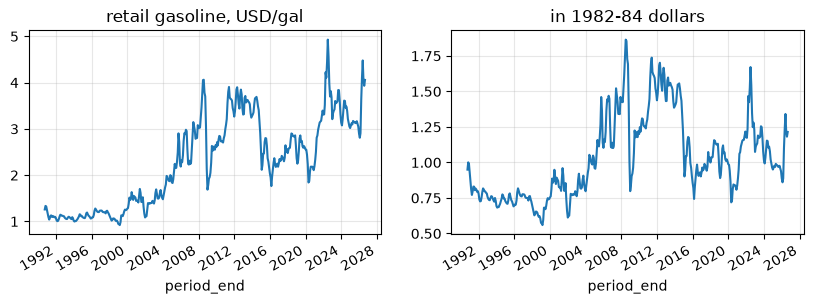

In [42]:
fig, axes = plt.subplots(1, 2)
prices["retail_price"].plot(ax=axes[0], title="retail gasoline, USD/gal")
prices["real_price"].plot(ax=axes[1], title="in 1982-84 dollars");

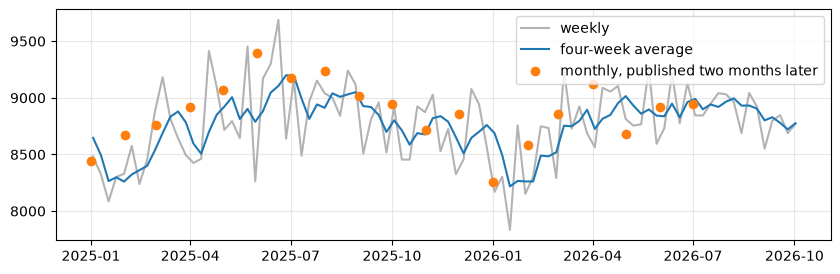

In [43]:
week = sql.query("""
    SELECT period_end, value FROM predictors
    WHERE product = 'gasoline' AND variable = 'product_supplied_weekly'
""").set_index("period_end")["value"].sort_index()
week.index = pd.to_datetime(week.index)
fig, ax = plt.subplots()
ax.plot(week.loc["2025":], color="0.7", label="weekly")
ax.plot(week.rolling("28D").mean().loc["2025":], label="four-week average")
ax.plot(gasoline["demand"].loc["2025":], "o", label="monthly, published two months later")
ax.legend();

In [44]:
# the weekly series averaged over each month, against the official monthly figure, % gap
(100 * (week.resample("MS").mean() / gasoline["demand"] - 1)).abs().describe().round(2)

count   319.00
mean      1.46
std       1.27
min       0.00
25%       0.53
50%       1.19
75%       2.07
max      11.33
dtype: float64

In [45]:
# Singapore: monthly tonnes over the days in the month, so February is not a demand drop
sql.query("""
    SELECT period_end, value * day(period_end) AS kt_month, value AS kt_day
    FROM demand
    WHERE product = 'bunker' AND period_end BETWEEN DATE '2025-01-01' AND DATE '2025-04-30'
    ORDER BY period_end
""")

,period_end,kt_month,kt_day
0,2025-01-31,"4,195.47",135.34
1,2025-02-28,"3,796.67",135.60
2,2025-03-31,"4,096.56",132.15
3,2025-04-30,"4,046.19",134.87


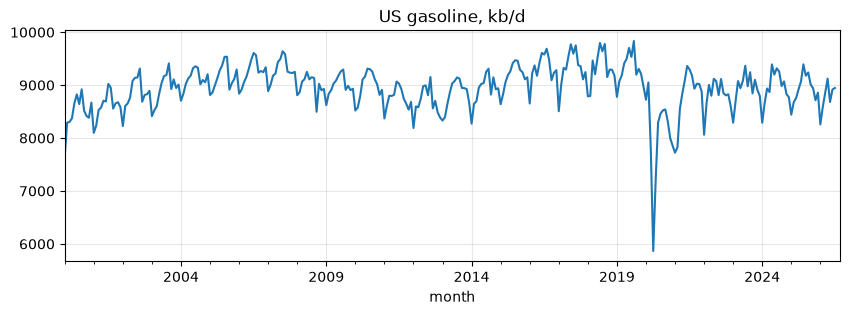

In [46]:
gasoline["demand"].plot(title="US gasoline, kb/d");

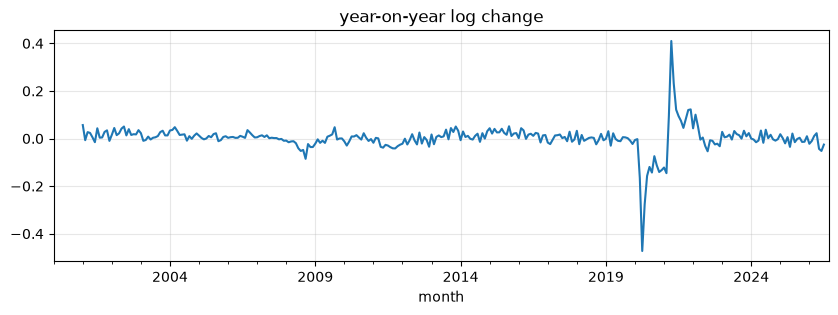

In [47]:
np.log(gasoline["demand"]).diff(12).plot(title="year-on-year log change");

In [48]:
demand = pd.DataFrame({"gasoline": gasoline["demand"], "distillate": distillate["demand"],
                       "bunker": bunker["demand"]})
history = demand.loc[:c.BACKTEST_START]  # before the backtest
yoy = np.log(history).diff(12)
pd.DataFrame({"level acf1": history.apply(lambda s: s.autocorr(1)),
              "level acf12": history.apply(lambda s: s.autocorr(12)),
              "yoy acf1": yoy.apply(lambda s: s.autocorr(1)),
              "yoy acf12": yoy.apply(lambda s: s.autocorr(12))}).round(2)

,level acf1,level acf12,yoy acf1,yoy acf12
gasoline,0.75,0.81,0.56,-0.03
distillate,0.72,0.54,0.65,-0.17
bunker,0.98,0.97,0.37,-0.06


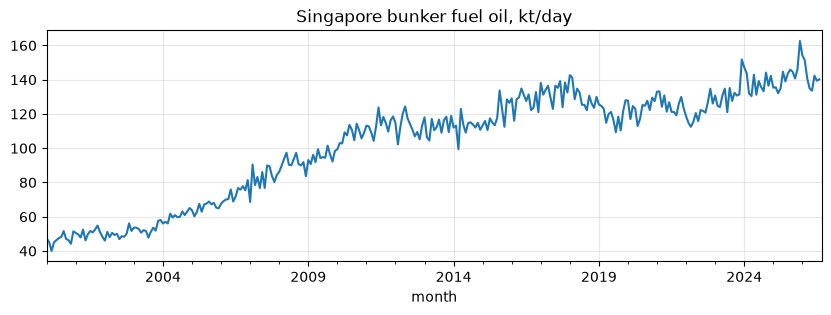

In [49]:
bunker["demand"].plot(title="Singapore bunker fuel oil, kt/day");

In [50]:
# a tree cannot forecast a level it has never seen: share of backtest months above the
# pre-backtest maximum. Hence the model's target: log demand over the seasonal naive
(demand.loc[c.BACKTEST_START:] > history.max()).mean().round(2)

gasoline     0.05
distillate   0.00
bunker       0.65
dtype: float64

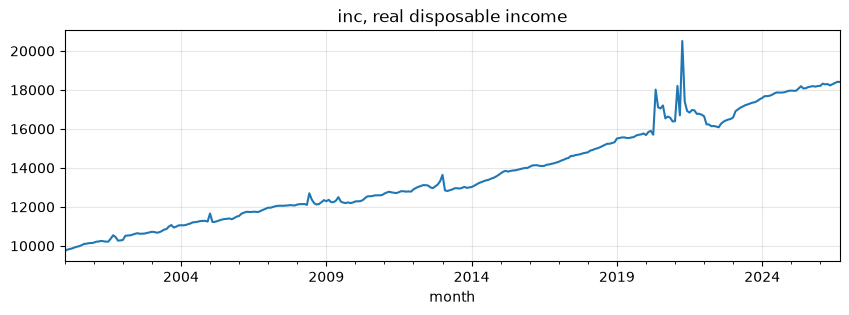

In [51]:
gasoline["inc"].plot(title="inc, real disposable income");

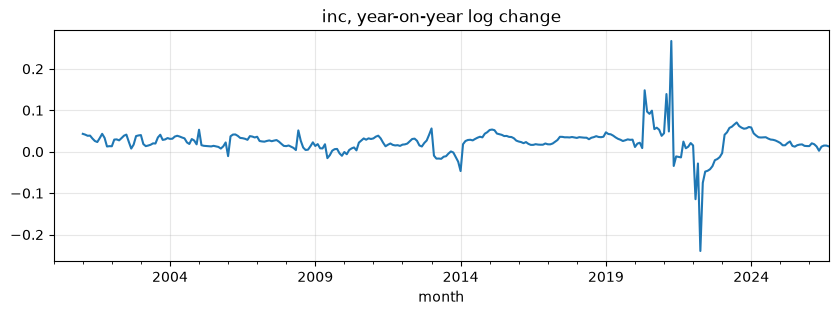

In [52]:
np.log(gasoline["inc"]).diff(12).plot(title="inc, year-on-year log change");

In [53]:
# degree days fall close to zero in summer, where a log change explodes: they enter as a
# year-on-year difference
distillate[["hdd", "hdd_oil"]].min()

hdd       2.00
hdd_oil   2.00
dtype: float64

In [54]:
drivers = distillate.columns.drop("demand")
train = distillate.loc[:c.BACKTEST_START, drivers]
train.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
hdd,181.00,361.27,317.49,2.00,39.00,302.00,660.00,999.00
hdd_oil,181.00,472.69,402.48,3.00,60.00,423.00,843.00,"1,323.00"
ind,181.00,95.00,4.69,84.75,91.24,94.17,99.10,103.71
ind_manuf,181.00,96.13,5.27,84.43,91.93,95.56,99.87,106.61
truck,178.00,83.71,6.32,72.50,79.10,84.35,86.75,99.30
real_price,181.00,1.27,0.38,0.65,0.87,1.29,1.64,2.15
product_supplied_4wk,181.00,"3,905.39",267.71,"3,299.50","3,719.00","3,890.75","4,104.75","4,658.50"


In [55]:
# standardised on the training sample only. Not used: a tree splits on thresholds, notebook 02
# checks it
scaled = (distillate[drivers] - train.mean()) / train.std()
scaled.loc[:c.BACKTEST_START].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
hdd,181.00,0.00,1.00,-1.13,-1.02,-0.19,0.94,2.01
hdd_oil,181.00,-0.00,1.00,-1.17,-1.03,-0.12,0.92,2.11
ind,181.00,-0.00,1.00,-2.18,-0.80,-0.18,0.87,1.86
ind_manuf,181.00,-0.00,1.00,-2.22,-0.80,-0.11,0.71,1.99
truck,178.00,-0.00,1.00,-1.77,-0.73,0.10,0.48,2.47
real_price,181.00,0.00,1.00,-1.65,-1.06,0.03,0.98,2.31
product_supplied_4wk,181.00,0.00,1.00,-2.26,-0.70,-0.05,0.74,2.81


## Final check

In [56]:
gasoline.shape, distillate.shape, bunker.shape

((321, 6), (321, 8), (321, 7))

In [57]:
gasoline.index.min(), gasoline.index.max(), bunker.index.min(), bunker.index.max()

(Timestamp('2000-01-01 00:00:00'),
 Timestamp('2026-09-01 00:00:00'),
 Timestamp('2000-01-01 00:00:00'),
 Timestamp('2026-09-01 00:00:00'))

In [58]:
gasoline.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
demand,319.00,"8,949.00",425.10,"5,866.00","8,719.00","9,005.00","9,218.00","9,834.00"
inc,321.00,"13,733.50","2,523.10","9,735.90","11,751.90","13,029.60","15,718.10","20,510.30"
payrolls,321.00,"140,850.80","9,433.80","129,706.00","132,344.00","137,847.00","148,742.00","159,015.00"
vmt,321.00,"254,176.00","21,428.00","167,617.00","240,281.00","256,392.00","267,574.00","297,770.00"
real_price,321.00,1.10,0.30,0.60,0.90,1.10,1.30,1.90
product_supplied_4wk,321.00,"8,940.30",448.50,"5,329.20","8,699.00","8,984.80","9,210.80","9,777.20"


In [59]:
distillate.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
demand,319.00,"3,928.30",219.40,"3,369.00","3,763.00","3,929.00","4,073.00","4,582.00"
hdd,321.00,351.90,311.60,2.00,36.00,286.00,629.00,999.00
hdd_oil,321.00,463.90,398.50,2.00,54.00,408.00,839.00,"1,323.00"
ind,321.00,97.30,4.70,84.60,93.00,99.00,101.00,104.10
ind_manuf,321.00,97.00,4.50,79.90,94.00,98.00,99.80,106.60
truck,318.00,95.80,15.00,72.50,83.10,92.90,113.00,120.40
real_price,321.00,1.30,0.30,0.60,1.00,1.20,1.50,2.20
product_supplied_4wk,321.00,"3,894.20",255.30,"3,214.00","3,713.80","3,887.80","4,078.00","4,658.50"


In [60]:
bunker.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
demand,320.00,102.50,31.10,40.00,75.70,113.20,126.60,162.60
brent,321.00,67.50,27.90,18.70,46.60,66.90,84.10,133.60
bunker_calls,321.00,"2,870.20",651.10,"1,587.00","2,297.00","3,130.00","3,385.00","3,829.00"
bunker_calls_gt,321.00,"125,707.30","51,842.20","40,236.00","73,040.20","137,890.40","168,390.00","210,383.40"
cargo,321.00,"43,195.00","8,711.80","23,217.00","37,211.70","46,243.70","50,066.60","55,976.10"
tankers,296.00,"1,841.60",266.00,"1,235.00","1,618.00","1,877.00","2,046.00","2,507.00"
wtr,319.00,84.80,16.30,52.70,73.20,86.30,97.40,116.80


Dataset ready for modelling.